In [1]:
from typing import TYPE_CHECKING
if TYPE_CHECKING:
    from icecream import ic  # noqa: F401

import sys

sys.path.append("..")

import numpy as np
import utils.debug  # noqa: F401

from utils.harmonic import (
    get_harmonic_oscillation,
    get_single_rect_oscillation,
)
from utils.plotting import show_subplots, show_multi_plot, show_plot
from utils.sampling import get_linspace
from utils.fourier import get_fourier_transform
from utils.convolution import (
    get_convolution,
    get_convolution_product,
    get_convolution_series,
    get_rect_convolution_limits,
    get_rect_convolution_analytic,
)

# 1 Вычисление интеграла свертки

В данной практике выполняется вычисление интеграла свертки и визуализируются промежуточные вычисления.

## 1.1 Вычисление интеграла свертки аналитическим способом

Для временных функций $s_1(t)$ и $s_2(t)$ задайте временные параметры и выполните по шагам вычисление интеграла свертки задавая пределы интегрирования.

In [2]:
A1, W1 = 1, 1
A2, W2 = 1, 1
T_STEPS = (-1.5, -0.5, 0.5, 1.5)

ic(A1, W1, A2, W2)

ic| A1: 1, W1: 1, A2: 1, W2: 1


(1, 1, 1, 1)

**Шаг 1.** Оба сигнала — прямоугольные импульсы с центром в нуле: $s_1(t)=A_1$ при $|t|\le W_1/2$ и $s_2(t)=A_2$ при $|t|\le W_2/2$. Тогда $s_1(t-\tau)=A_1$ при $t-W_1/2\le\tau\le t+W_1/2$, а $s_2(\tau)=A_2$ при $-W_2/2\le\tau\le W_2/2$. Произведение $s_2(\tau)s_1(t-\tau)$ отлично от нуля только там, где эти промежутки пересекаются.

**Шаг 2.** Пределы интегрирования:

$\tau_{\min}=\max(-W_2/2,\ t-W_1/2)$, $\tau_{\max}=\min(W_2/2,\ t+W_1/2)$.

In [3]:
for t in T_STEPS:
    lower, upper = get_rect_convolution_limits(W1, W2, t)
    ic(t, lower, upper)

ic| t: -1.5, lower: -0.5, upper: -1.0
ic| t: -0.5, lower: -0.5, upper: 0.0
ic| t: 0.5, lower: 0.0, upper: 0.5
ic| t: 1.5, lower: 1.0, upper: 0.5


**Шаг 3.** Если $\tau_{\min}<\tau_{\max}$, интеграл от константы $A_1A_2$ равен $A_1A_2(\tau_{\max}-\tau_{\min})$, иначе пересечения нет и интеграл равен нулю.

In [4]:
for t in T_STEPS:
    ic(t, get_rect_convolution_analytic(A1, W1, A2, W2, t))

ic| t: -1.5, get_rect_convolution_analytic(A1, W1, A2, W2, t): 0.0
ic| t: -0.5, get_rect_convolution_analytic(A1, W1, A2, W2, t): 0.5
ic| t: 0.5, get_rect_convolution_analytic(A1, W1, A2, W2, t): 0.5
ic| t: 1.5, get_rect_convolution_analytic(A1, W1, A2, W2, t): 0.0


**Шаг 4.** Результат по участкам (при $W_1=W_2=1$, $A_1=A_2=1$):

- $t<-1$: $0$;
- $-1\le t\le 0$: $\int_{-0.5}^{t+0.5}d\tau=t+1$;
- $0\le t\le 1$: $\int_{t-0.5}^{0.5}d\tau=1-t$;
- $t>1$: $0$.

Свёртка двух одинаковых прямоугольных импульсов — треугольный импульс длительности 2 с и высоты 1.

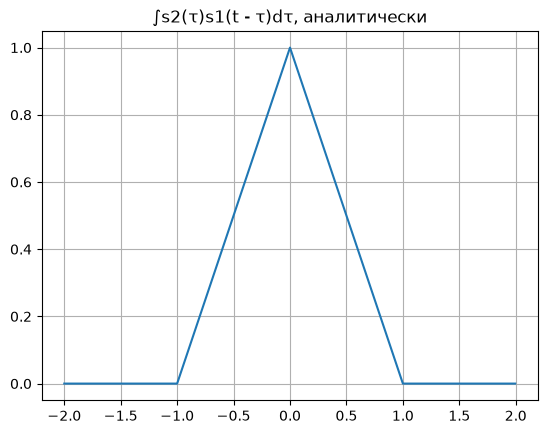

In [5]:
t_analytic = get_linspace(start=-2, stop=2, fs=800)
analytic = np.array([get_rect_convolution_analytic(A1, W1, A2, W2, t) for t in t_analytic])

show_plot(t=t_analytic, func_val=analytic, title="∫s2(τ)s1(t - τ)dτ, аналитически")

## 1.2 Вычисление интеграла свертки численным интегрированием

### 1.2.1 Формирование функции $s_1(t)$

Сформируйте функцию $s_1(t)$ как функцию времени $t$ (прямоугольный импульс длительности 1 сек).

In [6]:
TAU_START = -5
TAU_STOP = 5
TAU_FS = 20000
T_SAMPLES = (-1, 0, 2)
T_INTEGRAL = 0.2

In [7]:
tau = get_linspace(start=TAU_START, stop=TAU_STOP, fs=TAU_FS)

s1 = get_single_rect_oscillation(a=1, tau=1)
s2 = get_single_rect_oscillation(a=1, tau=1)

### 1.2.2 График $s_1(-\tau)$

Сделайте замену переменной $t$ на $\tau$ и изобразите график функции $s_1(-\tau)$.

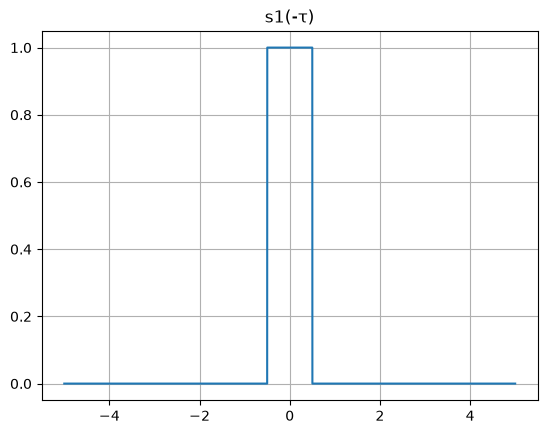

In [8]:
show_plot(t=tau, func_val=s1(-tau), title="s1(-τ)")

### 1.2.3 График $s_1(t - \tau)$

Изобразите график функции $s_1(t - \tau)$ для значений $t = -1, 0, 2$.

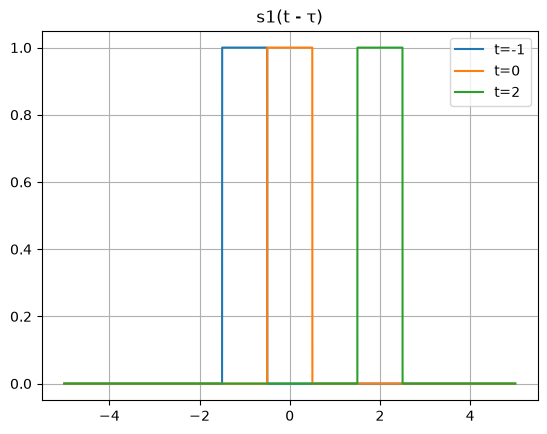

In [9]:
show_multi_plot(
    t=tau,
    func_vals=[s1(t - tau) for t in T_SAMPLES],
    labels=[f"t={t}" for t in T_SAMPLES],
    title="s1(t - τ)",
)

### 1.2.4 Произведение $s_2(\tau)s_1(t - \tau)$

Вычислите произведение функций $s_2(\tau)s_1(t - \tau)$ для значений $t = -1, 0, 2$ в интервале $-5 \le \tau \le 5$.

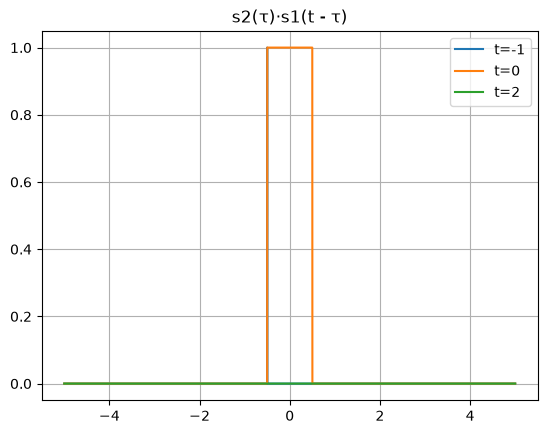

In [10]:
# products = [s2(tau) * s1(t - tau) for t in T_SAMPLES]
products = [get_convolution_product(s1, s2, tau, t) for t in T_SAMPLES]

show_multi_plot(
    t=tau,
    func_vals=products,
    labels=[f"t={t}" for t in T_SAMPLES],
    title="s2(τ)·s1(t - τ)",
)

### 1.2.5 Интеграл при $t = 0.2$

Вычислите интеграл $\int_{-5}^{5} s_2(\tau)s_1(t - \tau)d\tau$ для значения $t = 0.2$.

In [11]:
ic(T_INTEGRAL, get_convolution(s1, s2, tau, T_INTEGRAL)); # интеграл s2(tau) * s1(t - tau) 

ic| T_INTEGRAL: 0.2
    get_convolution(s1, s2, tau, T_INTEGRAL): np.float64(0.8004999999995563)


### 1.2.6 Интеграл как функция $t$

Вычислите интеграл $\int_{-5}^{5} s_2(\tau)s_1(t - \tau)d\tau$ для $t$ в интервале $(-1, 2)$. Изобразите результат как функцию времени $t$.

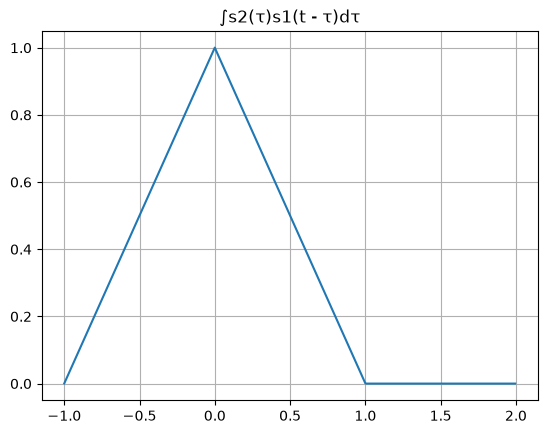

In [12]:
t_values = get_linspace(start=-1, stop=2, fs=600)
convolution = get_convolution_series(s1, s2, tau, t_values)

show_plot(t=t_values, func_val=convolution, title="∫s2(τ)s1(t - τ)dτ")